In [2]:
import pandas as pd
import numpy as np
import  matplotlib.pyplot as plt
import seaborn as sns 

df = pd.read_csv("diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,Pedigree,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
df.shape

(768, 9)

In [4]:
df["Outcome"].value_counts()

Outcome
0    500
1    268
Name: count, dtype: int64

In [6]:
cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin" ,"BMI"]
(df[cols]==0).sum()

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

In [7]:
df[cols]=df[cols].replace(0, np.nan)
df[cols]=df[cols].fillna(df[cols].median())

(df[cols]==0).sum()

Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64

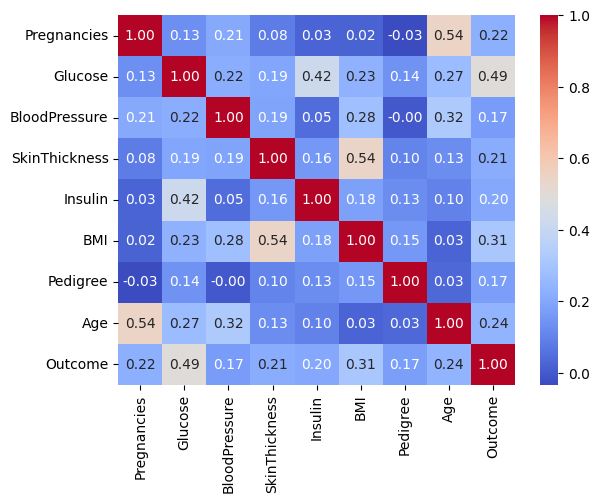

In [8]:
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop("Outcome", axis=1)
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print(X_train.shape, X_test.shape)

(614, 8) (154, 8)


In [10]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

y_predK = knn.predict(X_test)
y_predK[:10]

array([1, 0, 0, 1, 1, 1, 0, 0, 1, 0])

In [11]:
from sklearn.metrics import accuracy_score, precision_score, f1_score, recall_score, confusion_matrix

print("confusion matrix: ")
print(confusion_matrix(y_test, y_predK))

print("Accuracy: ", accuracy_score(y_test, y_predK))
print("Precision: ", precision_score(y_test, y_predK))
print("Recall score: ", recall_score(y_test, y_predK))
print("F1 score: ", f1_score(y_test, y_predK))
print("Error rate: ", 1-accuracy_score(y_test, y_predK))

confusion matrix: 
[[74 25]
 [18 37]]
Accuracy:  0.7207792207792207
Precision:  0.5967741935483871
Recall score:  0.6727272727272727
F1 score:  0.6324786324786325
Error rate:  0.27922077922077926


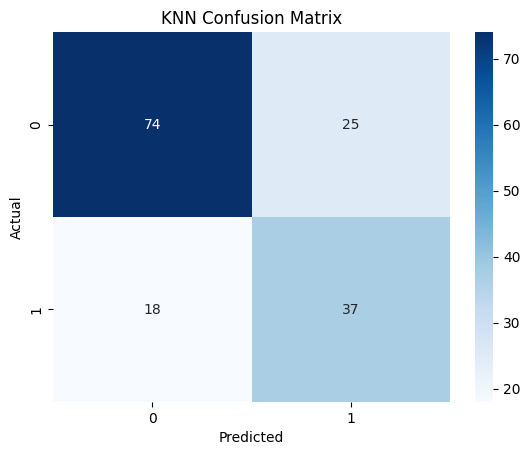

In [20]:
sns.heatmap(confusion_matrix(y_test, y_predK), annot=True, fmt="d", cmap="Blues")
plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()